In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap

In [2]:
train_df = pd.read_json('pan25-generative-ai-detection-task2-train/train.jsonl', lines=True)

In [4]:
train_df.head()

,text,language,label,source_dataset,model,label_text
0,Have you ever had to wait for something for a ...,English,4,TriBERT,chatgpt,deeply-mixed text; where some parts are writte...
1,"But now, things were not so simple._SEP_The gi...",English,3,RoFT_chatgpt,llm1-llm2,"human-initiated, then machine-continued"
2,"Dear Editor, I am writing to express my opini...",English,4,TriBERT,chatgpt,deeply-mixed text; where some parts are writte...
3,Humans once wielded formidable magical power. ...,English,4,Coauthor,gpt-3,deeply-mixed text; where some parts are writte...
4,"Here is a way that I had to be patient, and we...",English,4,TriBERT,chatgpt,deeply-mixed text; where some parts are writte...


In [5]:
# text features (single pass over train)
text_norm = train_df["text"].astype(str).str.replace("_SEP_", " ", regex=False)
train_df = train_df.assign(word_count=text_norm.str.split().str.len())

# shared constants for length plots
p99 = train_df["word_count"].quantile(0.99)

# label metadata (single pass)
order = list(range(6))
label_defs = (
    train_df.drop_duplicates("label")
    .set_index("label")["label_text"]
    .reindex(order)
)

def format_label(lbl: int, wrap_width: int | None = 25) -> str:
    """Bar chart: wrapped definition under id. KDE legend: pass wrap_width=None."""
    text = str(label_defs.loc[lbl])
    if wrap_width is None:
        return f"{lbl}: {text}"
    wrapped = "\n".join(textwrap.wrap(text, width=wrap_width))
    return f"{lbl}\n{wrapped}"

blue = plt.rcParams["axes.prop_cycle"].by_key()["color"][0]

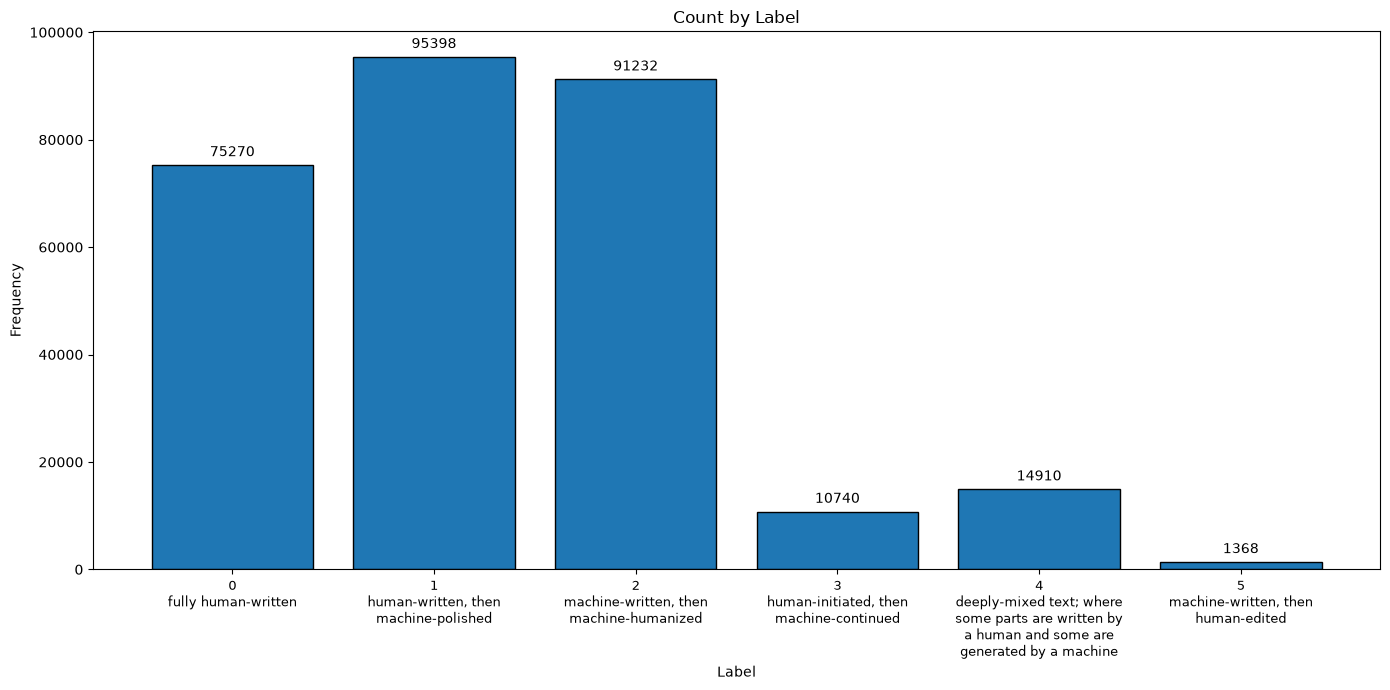

In [6]:
counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
    .reindex(order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(counts))
bars = ax.bar(x, counts.values, color=blue, edgecolor="black")

ax.set_xticks(x)
ax.set_xticklabels([format_label(i, wrap_width=25) for i in counts.index], fontsize=9)
ax.set_xlabel("Label")
ax.set_ylabel("Frequency")
ax.set_title("Count by Label")

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

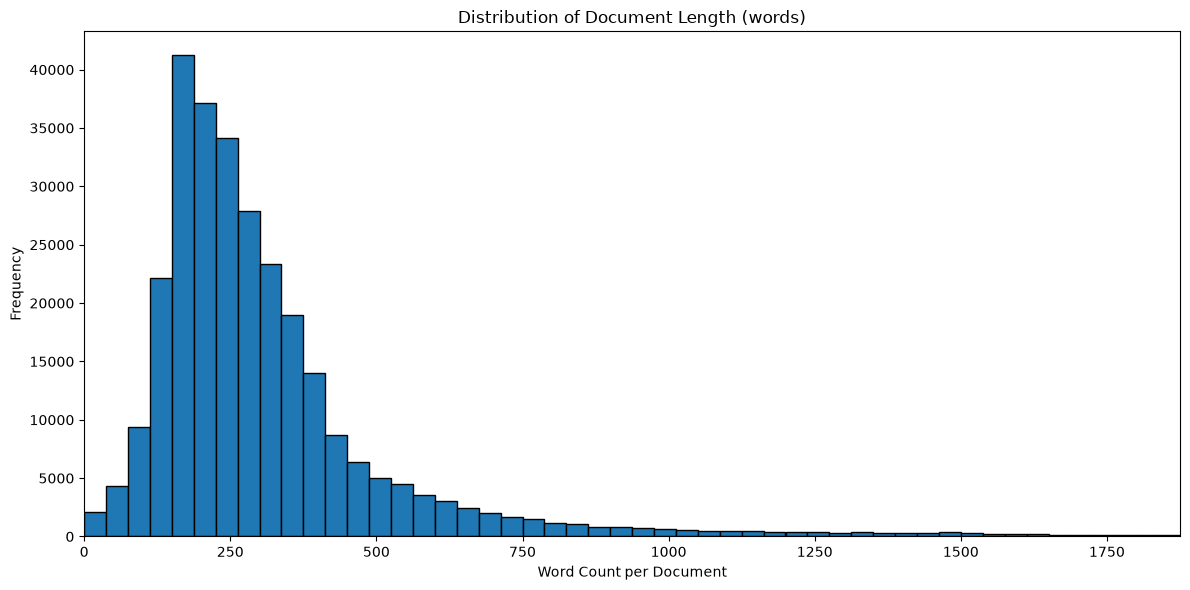

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(
    train_df["word_count"],
    bins=50,
    range=(0, p99),
    color=blue,
    edgecolor="black",
)
ax.set_xlim(0, p99)
ax.set_xlabel("Word Count per Document")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Document Length (words)")
plt.tight_layout()
plt.show()

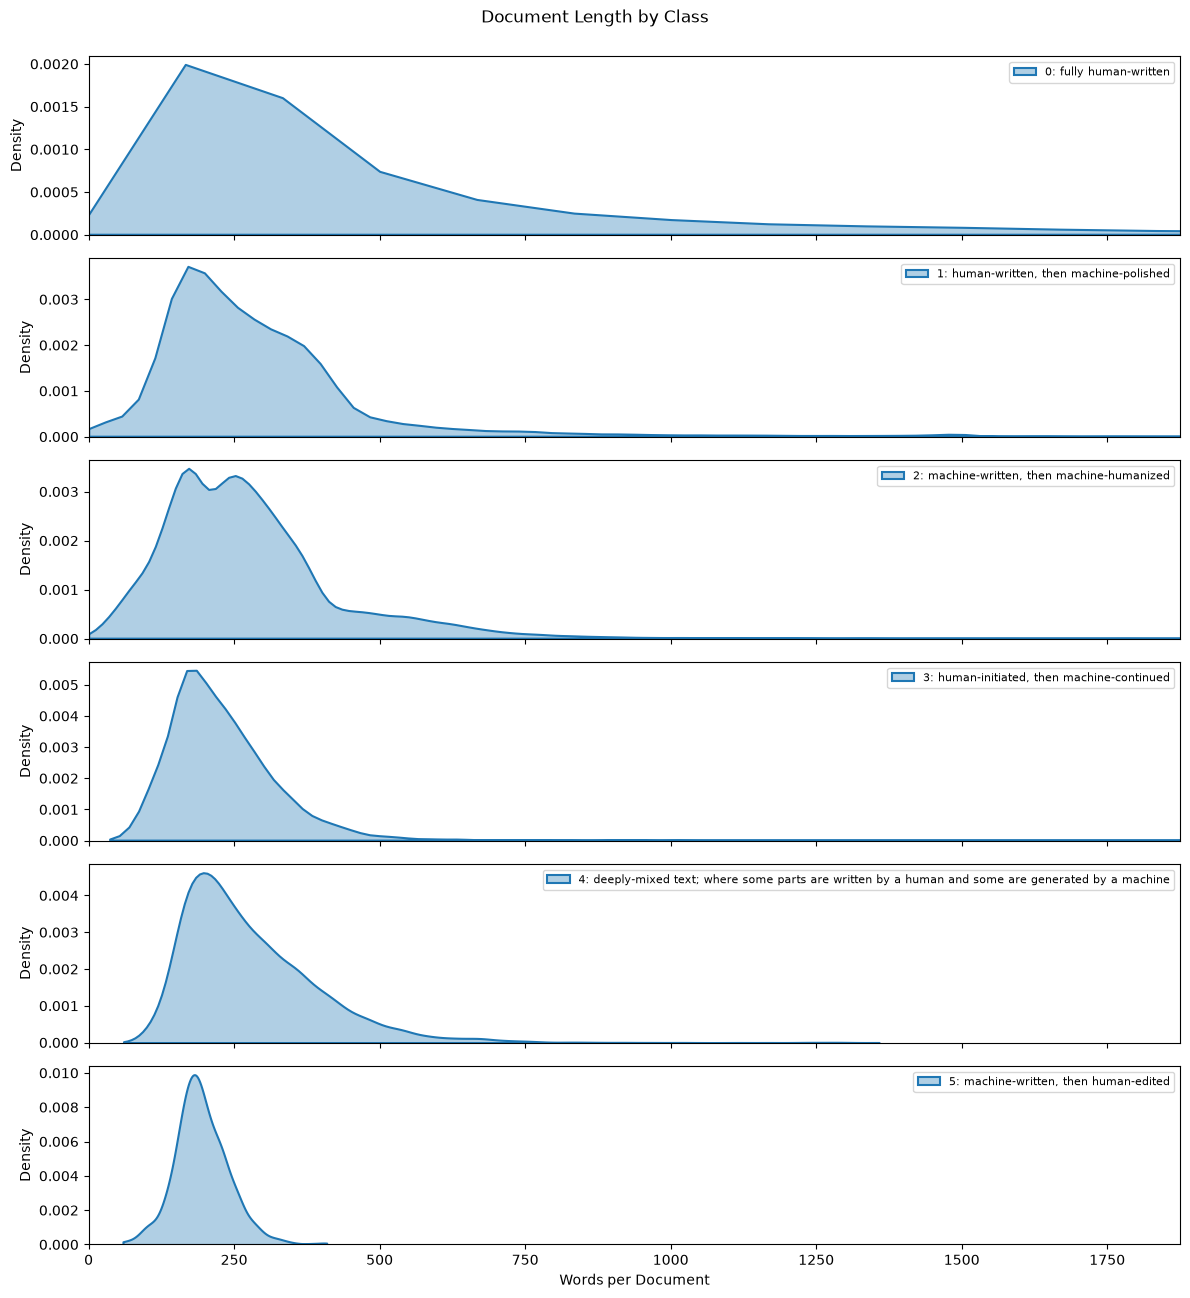

In [8]:
n = len(order)
fig, axes = plt.subplots(n, 1, figsize=(12, 2.2 * n), sharex=True)
if n == 1:
    axes = [axes]

for ax, lbl in zip(axes, order):
    vals = train_df.loc[train_df["label"] == lbl, "word_count"]
    sns.kdeplot(
        x=vals,
        ax=ax,
        color=blue,
        fill=True,
        alpha=0.35,
        linewidth=1.5,
        label=format_label(lbl, wrap_width=None),
        cut=0,
    )
    ax.set_ylabel("Density")
    ax.set_xlim(0, p99)
    ax.legend(loc="upper right", fontsize=8, frameon=True)

axes[-1].set_xlabel("Words per Document")
fig.suptitle("Document Length by Class")
fig.subplots_adjust(hspace=0.15)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [ ]:
# text_norm = train_df["text"].astype(str).str.replace("_SEP_", " ", regex=False)
# train_df = train_df.assign(word_count=text_norm.str.split().str.len())

# order = list(range(6))
# p99 = train_df["word_count"].quantile(0.99)

# # Subsample per class (keeps label column — safe on pandas 3.x)
# sample = pd.concat(
#     [
#         g.sample(n=min(8000, len(g)), random_state=42)
#         for _, g in train_df.groupby("label", sort=True)
#     ],
#     ignore_index=True,
# )

# # Optional: trim extreme lengths so KDE isn't dominated by outliers
# sample_plot = sample[sample["word_count"] <= p99]

# fig, ax = plt.subplots(figsize=(12, 6))

# sns.kdeplot(
#     data=sample_plot,
#     x="word_count",
#     hue="label",
#     hue_order=order,
#     common_norm=False,
#     fill=True,
#     alpha=0.25,
#     linewidth=1.5,
#     ax=ax,
# )

# ax.set_xlim(0, p99)
# ax.set_xlabel("words per document")
# ax.set_ylabel("density")
# ax.set_title("Document length by class (overlaid KDE, ≤8k samples per label)")
# ax.legend(title="label", bbox_to_anchor=(1.02, 1), loc="upper left")
# plt.tight_layout()
# plt.show()